# 03 · Implemented Visual System & Before-and-After Redesigns (W3 Integration)

**Study:** Lag-Safe & Nowcasted Two-Week-Ahead (`t+2`) Forecasting of Respiratory Emergency Visits in Chile (`IdCausa = 2`)  
**Team:** Group 02 — Benjamín Pinto & Sebastián Herrera · **Course:** IIB423T-1 Business Intelligence (UDD)

### Purpose of This Notebook (Criterion C · Implemented Visual System)
1. Define the **target audience**, **common operational purpose**, and **Munzner task abstraction** (Class 09 verbs: `identify`, `compare`, `locate`, `summarize`) linking all three views.
2. Import our shared design module [`src/visual_system.py`](../src/visual_system.py) and apply its exact rules (5-role colorblind-safe palette, grayscale-safe non-color redundancy, uniform frameless top-bar legends, zero-based axes, qualified titles) to generate and display all **3 final views** and **3 Before-and-After comparisons** inline—**visible without running code**.
3. Export publication-ready **300-dpi PNGs and editable SVGs** to `figures/` so the notebook, repository, and C3 slides stay 100% synchronized.
4. Document the required 4-part **Limitation → Possible Misunderstanding → Reason to Keep → Next Improvement** audit for each final view.

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.image as mpimg
from matplotlib.lines import Line2D

REPO_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))
from src.visual_system import (PALETTE, SERIES_STYLE, apply_system_rc, style_axes, add_header_footer,
                               add_top_legend, series_line, series_marker, series_handle)

# Location of the W3 v2 summary extracts (kept outside this repository per the no-data policy)
_w3_candidates = [REPO_ROOT.parent / 'GROUP_02_W3_Final' / 'GROUP_02_W3_v2', REPO_ROOT.parent / 'GROUP_02_W3_v2']
W3_V2_DIR = Path(os.environ.get('W3_V2_DIR', next((c for c in _w3_candidates if c.exists()), _w3_candidates[0])))
DATA_DIR = W3_V2_DIR / 'data'
FIG_OUT = REPO_ROOT / 'figures'
FIG_OUT.mkdir(parents=True, exist_ok=True)

# Load exact verified outputs used by Views 1-3 (not stored in repository per no-data policy)
lag_df = pd.read_csv(DATA_DIR / 'publication_lag_probe_2026-11-04.csv')
nat_df = pd.read_csv(DATA_DIR / 'w3_v2_test_2024_weekly_national.csv', parse_dates=['target_week_start'])
cs_df = pd.read_csv(DATA_DIR / 'w3_v2_test_mae_by_care_setting.csv')

print('Shared Visual System PALETTE tokens imported from src/visual_system.py:')
for k, v in list(PALETTE.items())[:5]:
    print(f'  {k:10s} -> {v}')

Shared Visual System PALETTE tokens imported from src/visual_system.py:
  observed   -> #111827
  model      -> #0072B2
  nowcast    -> #1B9E77
  baseline   -> #6B7280
  alert      -> #C0392B


## 1. Audience, Purpose, Tasks & Shared Visual Rules

* **Audience:** MINSAL & Servicio de Salud **Emergency Network Operations Managers** (Monday-morning staffing & surge-readiness meeting across `633` facilities).
* **Common Purpose:** Decide **when and where** to rely on the Monday-nowcasted `t+2` forecast (`MAE 30.57`, `−40.4%` vs. baseline) vs. activate manual surge monitoring.
* **Shared Visual System Rules (enforced via `src/visual_system.py`):**
  1. **Consistent 5-Role Palette:** `#111827` Observed · `#0072B2` Updated Model / Settled Lags · `#1B9E77` Simulated Nowcast Zone · `#6B7280` Baseline / Neutral Ref (`+ Over-forecast`) · `#C0392B` Alert / Caution (`Excluded Age 1`, `2-wk lag`, `− Under-forecast shortage risk`, `Oct overshoot`, `CEAR n=31`).
  2. **Non-Color Redundancy:** Distinct line styles, marker shapes (`o`, `s`, `D`, `X`, `^`), hatch patterns (`xxx`, `...`, `///`), and `[!]` text tags keep all distinctions legible in grayscale. Time-series roles are fixed once in `SERIES_STYLE` (`src/visual_system.py`) and reused by Views 2–3:

     | Series role | Color | Line style | Marker |
     |---|---|---|---|
     | Observed (DEIS) | `#111827` near-black | **solid** `—` | filled circle `●` |
     | Model (XGBoost + Sim. Nowcast) | `#0072B2` blue | **dotted** `···` | filled diamond `◆` |
     | Baseline (same as week t−1) | `#6B7280` slate | **dashed** `– –` | hollow square `□` |

     *C3 fix (W3 feedback, criterion C):* in W3 v2, View 2 drew Observed and Model with the same solid line and the same filled circle, so only color separated them. They now differ in line style **and** marker shape, so the three series remain distinguishable in grayscale.
  3. **Uniform Layout & Scales:** `DejaVu Sans`, qualified interpretive title, context subtitle with `n`/period, **frameless single-row top-bar legend** above every plot, and **zero-based magnitude axes** (`0–100%`, `0–235k`, `0–100 MAE`).

## 2. View 1 — Monday Data Readiness & Simulated Nowcast Window (Before → After)

* **Task (Class 09):** **Identify** completeness across reporting ages (`1–21`), **compare** partial week $t$ (`94.3%`) vs. settled week $t-1$ (`99.1%`), and **locate** the simulated nowcast window (`ages 2–8`) vs. excluded Age 1 (`17%`).
* **Redesign Changes (Classes 09–11):** Replaced generic topic title and uncoded pink/mint fills with qualified title, transparent Wed-to-Mon re-mapping subtitle, shared top-bar legend, two dotted cutoffs (`1.5` & `8.5` days), patterned bands (`xxx` vs. `...`), and redundant marker shapes (`X`, `D`, `o`, `s`).

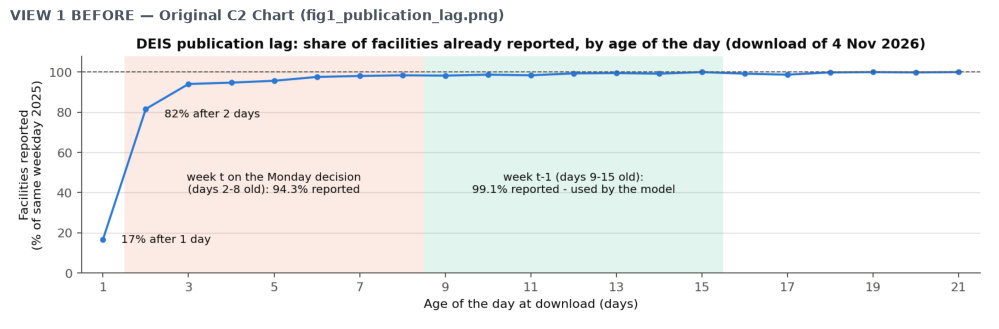

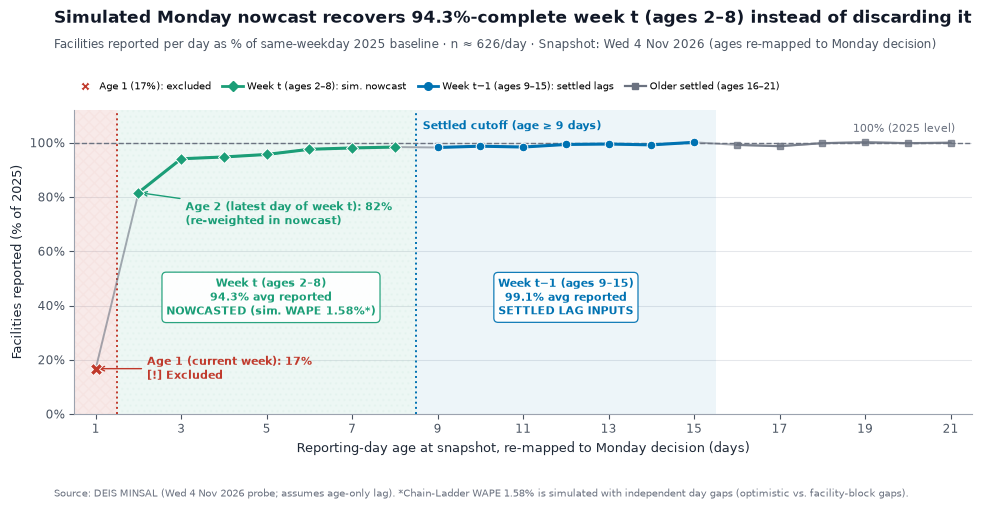

In [2]:
# Display BEFORE (original C2 fig1_publication_lag.png)
before1 = mpimg.imread(W3_V2_DIR / 'figures' / 'view1_before_publication_lag.png')
fig_b1, ax_b1 = plt.subplots(figsize=(10.2, 3.3))
ax_b1.imshow(before1); ax_b1.axis('off')
ax_b1.set_title('VIEW 1 BEFORE — Original C2 Chart (fig1_publication_lag.png)', fontsize=10, fontweight='bold', loc='left', color=PALETTE['muted'])
plt.tight_layout(); plt.show()

# Generate & display AFTER via src/visual_system.py
apply_system_rc()
lag = lag_df.loc[lag_df['days_before_probe'].between(1, 21)].sort_values('days_before_probe').copy()
lag['pct'] = lag['facility_ratio'] * 100.0

fig, ax = plt.subplots(figsize=(10.2, 5.15))
fig.subplots_adjust(left=0.08, right=0.96, top=0.77, bottom=0.18)
style_axes(ax, grid_axis='y')

ax.axvspan(0.5, 1.5, facecolor=PALETTE['alert'], alpha=0.10, hatch='xxx', edgecolor='#E6B0AA', lw=0.0, zorder=1)
ax.axvspan(1.5, 8.5, facecolor=PALETTE['nowcast'], alpha=0.08, hatch='...', edgecolor='#A7D7C5', lw=0.0, zorder=1)
ax.axvspan(8.5, 15.5, facecolor=PALETTE['model'], alpha=0.07, zorder=1)
ax.axvline(1.5, color=PALETTE['alert'], ls=':', lw=1.4, zorder=3)
ax.axvline(8.5, color=PALETTE['model'], ls=':', lw=1.4, zorder=3)
ax.axhline(100.0, color=PALETTE['baseline'], ls='--', lw=1.0, zorder=2)

ax.plot(lag['days_before_probe'], lag['pct'], color=PALETTE['baseline'], lw=1.4, alpha=0.6, zorder=3)
d1 = lag.loc[lag['days_before_probe'] == 1]
wk_t = lag.loc[lag['days_before_probe'].between(2, 8)]
wk_t1 = lag.loc[lag['days_before_probe'].between(9, 15)]
older = lag.loc[lag['days_before_probe'] >= 16]

ax.plot(d1['days_before_probe'], d1['pct'], color=PALETTE['alert'], lw=0, marker='X', ms=8.0,
        mfc=PALETTE['alert'], mec='white', mew=0.6, zorder=5)
ax.plot(wk_t['days_before_probe'], wk_t['pct'], color=PALETTE['nowcast'], lw=2.2, marker='D', ms=5.8,
        mfc=PALETTE['nowcast'], mec='white', mew=0.7, zorder=5)
ax.plot(wk_t1['days_before_probe'], wk_t1['pct'], color=PALETTE['model'], lw=2.2, marker='o', ms=6.2,
        mfc=PALETTE['model'], mec='white', mew=0.7, zorder=5)
ax.plot(older['days_before_probe'], older['pct'], color=PALETTE['baseline'], lw=1.6, marker='s', ms=5.0,
        mfc=PALETTE['baseline'], alpha=0.75, zorder=4)

p1, p2 = d1['pct'].iloc[0], wk_t.loc[wk_t['days_before_probe'] == 2, 'pct'].iloc[0]
ax.annotate(f'Age 1 (current week): {p1:.0f}%\n[!] Excluded', xy=(1, p1), xytext=(2.2, 13),
            fontsize=8.1, fontweight='bold', color=PALETTE['alert'],
            arrowprops=dict(arrowstyle='->', color=PALETTE['alert'], lw=1.0))
ax.annotate(f'Age 2 (latest day of week t): {p2:.0f}%\n(re-weighted in nowcast)', xy=(2, p2), xytext=(3.1, 70),
            fontsize=8.0, fontweight='bold', color=PALETTE['nowcast'],
            arrowprops=dict(arrowstyle='->', color=PALETTE['nowcast'], lw=1.0))

ax.text(5.1, 43, 'Week t (ages 2–8)\n94.3% avg reported\nNOWCASTED (sim. WAPE 1.58%*)',
        ha='center', va='center', fontsize=8.1, fontweight='bold', color=PALETTE['nowcast'],
        bbox=dict(boxstyle='round,pad=0.38', facecolor='white', edgecolor=PALETTE['nowcast'], alpha=0.93, lw=0.9))
ax.text(12.0, 43, 'Week t−1 (ages 9–15)\n99.1% avg reported\nSETTLED LAG INPUTS',
        ha='center', va='center', fontsize=8.1, fontweight='bold', color=PALETTE['model'],
        bbox=dict(boxstyle='round,pad=0.38', facecolor='white', edgecolor=PALETTE['model'], alpha=0.93, lw=0.9))

ax.text(8.65, 105.0, 'Settled cutoff (age ≥ 9 days)', fontsize=7.9, fontweight='bold', color=PALETTE['model'], ha='left')
ax.text(21.1, 104.0, '100% (2025 level)', fontsize=7.6, color=PALETTE['baseline'], ha='right')

ax.set_xlim(0.5, 21.5); ax.set_ylim(0, 112)
ax.set_xticks(range(1, 22, 2)); ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.set_yticklabels(['0%', '20%', '40%', '60%', '80%', '100%'])
ax.set_xlabel('Reporting-day age at snapshot, re-mapped to Monday decision (days)')
ax.set_ylabel('Facilities reported (% of 2025)')

handles1 = [
    Line2D([0], [0], color='none', marker='X', ms=7, mfc=PALETTE['alert'], mec='white', label='Age 1 (17%): excluded'),
    Line2D([0], [0], color=PALETTE['nowcast'], lw=2.0, marker='D', ms=5.5, label='Week t (ages 2–8): sim. nowcast'),
    Line2D([0], [0], color=PALETTE['model'], lw=2.0, marker='o', ms=5.5, label='Week t−1 (ages 9–15): settled lags'),
    Line2D([0], [0], color=PALETTE['baseline'], lw=1.6, marker='s', ms=5.0, label='Older settled (ages 16–21)'),
]
add_top_legend(ax, handles1, ncol=4, y_offset=1.03, fontsize=7.4)
add_header_footer(
    fig,
    title='Simulated Monday nowcast recovers 94.3%-complete week t (ages 2–8) instead of discarding it',
    subtitle='Facilities reported per day as % of same-weekday 2025 baseline · n ≈ 626/day · Snapshot: Wed 4 Nov 2026 (ages re-mapped to Monday decision)',
    footer='Source: DEIS MINSAL (Wed 4 Nov 2026 probe; assumes age-only lag). *Chain-Ladder WAPE 1.58% is simulated with independent day gaps (optimistic vs. facility-block gaps).',
)
fig.savefig(FIG_OUT / 'view1_after_publication_lag.png', dpi=300)
fig.savefig(FIG_OUT / 'view1_after_publication_lag.svg')
plt.show()

## 3. View 2 — National 2024 Forecast Trajectory & Peak Lag (Before → After)

* **Task (Class 09):** **Summarize** the 52-week national trajectory, **compare** XGBoost + Sim. Nowcast and `t−1` baseline against observed visits, and **identify** the May peak plateau (`2-wk lag`) and `6 Oct` overshoot (`+28.4k`).
* **Redesign Changes (Classes 09–11):** Anchored top y-axis at **`0`** (`0–235k`), applied shared top-bar legend + direct end-of-line labels, annotated the flat May plateau (`182.0k` on 12 May vs. `183.7k` on 26 May), flagged the factual `6 Oct` overshoot without causal overclaims, and shaded the residual panel neutrally (`+ Over-forecast`) vs. red (`− Under-forecast / shortage risk`).
* **C3 fix (W3 feedback):** Observed and Model no longer share a solid line and a filled circle. Using the shared `SERIES_STYLE` roles, **Observed = solid + `●`**, **Model = dotted + `◆`**, **Baseline = dashed + `□`**, in both panels, at the highlighted peaks and in the legend, so the distinction no longer depends on color alone.

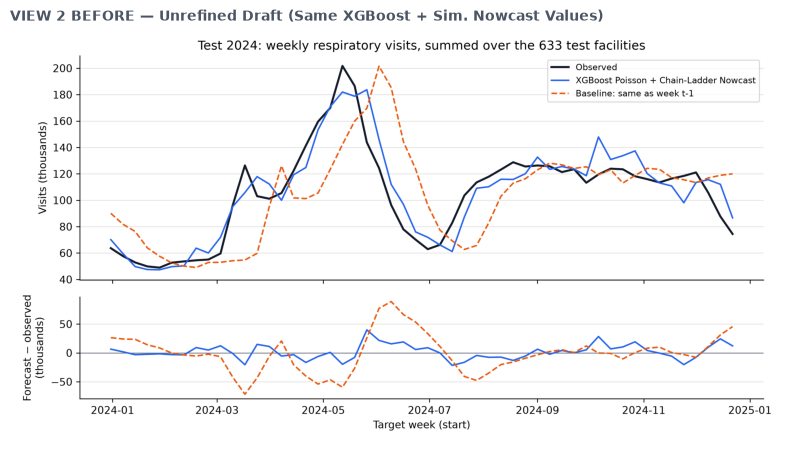

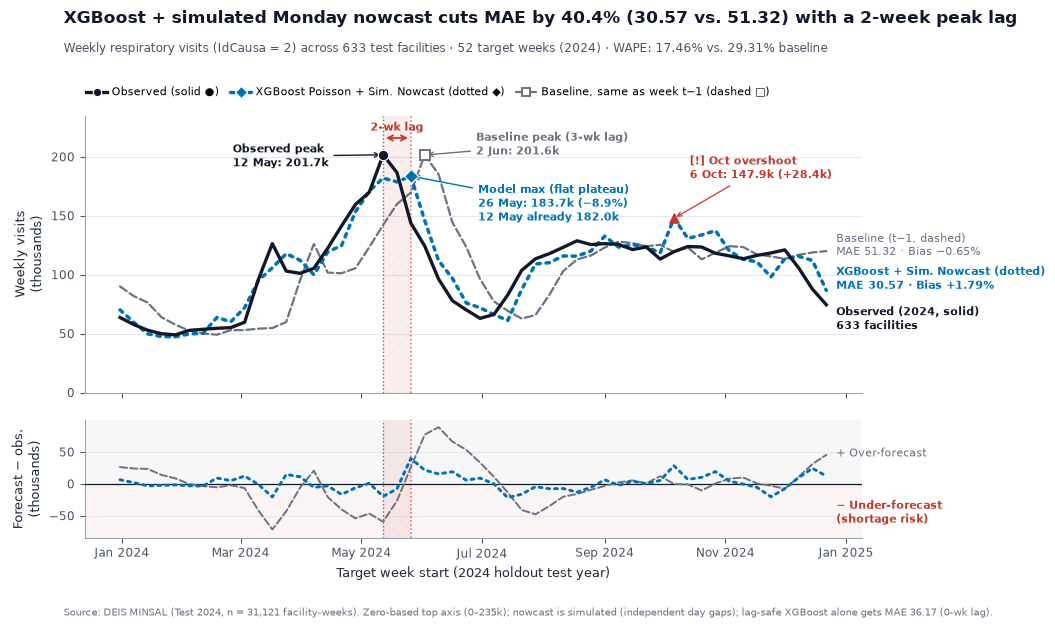

In [3]:
# Display BEFORE (unrefined draft with exact same values)
before2 = mpimg.imread(W3_V2_DIR / 'figures' / 'view2_before_national_forecast.png')
fig_b2, ax_b2 = plt.subplots(figsize=(10.2, 4.6))
ax_b2.imshow(before2); ax_b2.axis('off')
ax_b2.set_title('VIEW 2 BEFORE — Unrefined Draft (Same XGBoost + Sim. Nowcast Values)', fontsize=10, fontweight='bold', loc='left', color=PALETTE['muted'])
plt.tight_layout(); plt.show()

# Generate & display AFTER via src/visual_system.py
apply_system_rc()
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10.5, 6.4), sharex=True,
                               gridspec_kw={'height_ratios': [2.35, 1.0], 'hspace': 0.14})
fig.subplots_adjust(left=0.08, right=0.82, top=0.80, bottom=0.14)
style_axes(ax1, grid_axis='y'); style_axes(ax2, grid_axis='y')

obs_idx, xgb_idx, bas_idx = nat_df['target_resp'].idxmax(), nat_df['model_pred'].idxmax(), nat_df['baseline_pred'].idxmax()
obs_dt, obs_pk = nat_df.loc[obs_idx, 'target_week_start'], nat_df.loc[obs_idx, 'target_resp']
xgb_dt, xgb_pk = nat_df.loc[xgb_idx, 'target_week_start'], nat_df.loc[xgb_idx, 'model_pred']
bas_dt, bas_pk = nat_df.loc[bas_idx, 'target_week_start'], nat_df.loc[bas_idx, 'baseline_pred']
may12_mod = nat_df.loc[obs_idx, 'model_pred']

for ax in (ax1, ax2):
    ax.axvspan(obs_dt, xgb_dt, facecolor=PALETTE['alert'], alpha=0.08, hatch='///', edgecolor='#E6B0AA', lw=0.0, zorder=1)
    ax.axvline(obs_dt, color=PALETTE['observed'], ls=':', lw=1.0, alpha=0.6, zorder=2)
    ax.axvline(xgb_dt, color=PALETTE['alert'], ls=':', lw=1.1, alpha=0.75, zorder=2)

# Shared SERIES_STYLE roles: Observed = solid + circle, Model = dotted + diamond, Baseline = dashed + hollow square
ax1.plot(nat_df['target_week_start'], nat_df['target_resp'], **series_line('observed'), zorder=5)
ax1.plot(nat_df['target_week_start'], nat_df['model_pred'], **series_line('model'), zorder=4)
ax1.plot(nat_df['target_week_start'], nat_df['baseline_pred'], **series_line('baseline'), zorder=3)

ax1.plot([obs_dt], [obs_pk], **series_marker('observed', size=7.5), zorder=6)
ax1.plot([xgb_dt], [xgb_pk], **series_marker('model', size=7.0), zorder=6)
ax1.plot([bas_dt], [bas_pk], **series_marker('baseline', size=7.0), zorder=6)

ax1.annotate(f'Observed peak\n12 May: {obs_pk:.1f}k', xy=(obs_dt, obs_pk), xytext=(obs_dt - pd.Timedelta(days=76), 192),
             fontsize=8.0, fontweight='bold', color=PALETTE['observed'],
             arrowprops=dict(arrowstyle='->', color=PALETTE['observed'], lw=1.0))
ax1.annotate(f'Baseline peak (3-wk lag)\n2 Jun: {bas_pk:.1f}k', xy=(bas_dt, bas_pk), xytext=(bas_dt + pd.Timedelta(days=26), 202),
             fontsize=7.8, fontweight='bold', color=PALETTE['baseline'],
             arrowprops=dict(arrowstyle='->', color=PALETTE['baseline'], lw=1.0))
ax1.annotate(f'Model max (flat plateau)\n26 May: {xgb_pk:.1f}k (−8.9%)\n12 May already {may12_mod:.1f}k',
             xy=(xgb_dt, xgb_pk), xytext=(xgb_dt + pd.Timedelta(days=34), 146),
             fontsize=7.8, fontweight='bold', color=PALETTE['model'],
             arrowprops=dict(arrowstyle='->', color=PALETTE['model'], lw=1.0))

oct_row = nat_df.loc[nat_df['target_week_start'].dt.month == 10].sort_values('model_residual', ascending=False).iloc[0]
ax1.scatter([oct_row['target_week_start']], [oct_row['model_pred']], color=PALETTE['alert'], s=44, marker='^', zorder=6)
ax1.annotate(f"[!] Oct overshoot\n6 Oct: {oct_row['model_pred']:.1f}k (+{oct_row['model_residual']:.1f}k)",
             xy=(oct_row['target_week_start'], oct_row['model_pred']),
             xytext=(oct_row['target_week_start'] + pd.Timedelta(days=8), 182),
             fontsize=7.6, fontweight='bold', color=PALETTE['alert'],
             arrowprops=dict(arrowstyle='->', color=PALETTE['alert'], lw=0.9))

ax1.annotate('', xy=(xgb_dt, 216), xytext=(obs_dt, 216), arrowprops=dict(arrowstyle='<->', color=PALETTE['alert'], lw=1.3))
ax1.text(obs_dt + (xgb_dt - obs_dt) / 2, 220, '2-wk lag', ha='center', va='bottom', fontsize=8.0, fontweight='bold', color=PALETTE['alert'])

last_dt = nat_df['target_week_start'].iloc[-1] + pd.Timedelta(days=5)
ax1.text(last_dt, nat_df['baseline_pred'].iloc[-1] + 5, 'Baseline (t−1, dashed)\nMAE 51.32 · Bias −0.65%', fontsize=7.8, color=PALETTE['baseline'], va='center')
ax1.text(last_dt, nat_df['model_pred'].iloc[-1] + 10, 'XGBoost + Sim. Nowcast (dotted)\nMAE 30.57 · Bias +1.79%', fontsize=8.0, fontweight='bold', color=PALETTE['model'], va='center')
ax1.text(last_dt, nat_df['target_resp'].iloc[-1] - 12, 'Observed (2024, solid)\n633 facilities', fontsize=8.0, fontweight='bold', color=PALETTE['observed'], va='center')

handles2 = [
    series_handle('observed', 'Observed (solid ●)'),
    series_handle('model', 'XGBoost Poisson + Sim. Nowcast (dotted ◆)'),
    series_handle('baseline', 'Baseline, same as week t−1 (dashed □)'),
]
add_top_legend(ax1, handles2, ncol=3, y_offset=1.03, fontsize=7.6)
ax1.set_ylim(0, 235); ax1.set_yticks([0, 50, 100, 150, 200]); ax1.set_ylabel('Weekly visits\n(thousands)')

ax2.axhline(0, color=PALETTE['observed'], lw=0.9, zorder=3)
ax2.axhspan(0, 105, facecolor=PALETTE['baseline'], alpha=0.05, zorder=0)
ax2.axhspan(-90, 0, facecolor=PALETTE['alert'], alpha=0.05, zorder=0)
ax2.plot(nat_df['target_week_start'], nat_df['model_residual'], **series_line('model', lw=2.1), zorder=4)
ax2.plot(nat_df['target_week_start'], nat_df['baseline_residual'], **series_line('baseline', lw=1.4), zorder=3)
ax2.text(last_dt, 48, '+ Over-forecast', fontsize=7.8, color=PALETTE['baseline'], va='center')
ax2.text(last_dt, -45, '− Under-forecast\n(shortage risk)', fontsize=7.8, fontweight='bold', color=PALETTE['alert'], va='center')
ax2.set_ylim(-85, 100); ax2.set_yticks([-50, 0, 50]); ax2.set_ylabel('Forecast − obs.\n(thousands)')
ax2.set_xlabel('Target week start (2024 holdout test year)')
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=2)); ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

add_header_footer(
    fig,
    title='XGBoost + simulated Monday nowcast cuts MAE by 40.4% (30.57 vs. 51.32) with a 2-week peak lag',
    subtitle='Weekly respiratory visits (IdCausa = 2) across 633 test facilities · 52 target weeks (2024) · WAPE: 17.46% vs. 29.31% baseline',
    footer='Source: DEIS MINSAL (Test 2024, n = 31,121 facility-weeks). Zero-based top axis (0–235k); nowcast is simulated (independent day gaps); lag-safe XGBoost alone gets MAE 36.17 (0-wk lag).',
    title_y=0.965, sub_y=0.915, foot_y=0.015,
)
fig.savefig(FIG_OUT / 'view2_after_national_forecast.png', dpi=300)
fig.savefig(FIG_OUT / 'view2_after_national_forecast.svg')
plt.show()

## 4. View 3 — Facility-Level MAE Across Care Settings (Before → After)

* **Task (Class 09):** **Compare** paired MAE (XGBoost + Sim. Nowcast vs. `t−1` baseline) across all 5 care settings, and **identify** largest gains (`−36.4%` to `−42.4%`) vs. small-sample caveat (`CEAR`, `n = 31`).
* **Redesign Changes (Classes 09–11):** Converted alphabetical grouped vertical bars into an **ordered horizontal dumbbell chart** (Class 09 Slide 16) anchored at `0`, sharing View 2's exact series encoding and top-bar legend, embedding `n` and mean weekly volume on every row, flagging `CEAR` (`3.0 → 5.3 (+2.3)`, `[!] n=31`), and disclosing the `7` untyped rows in the footer.

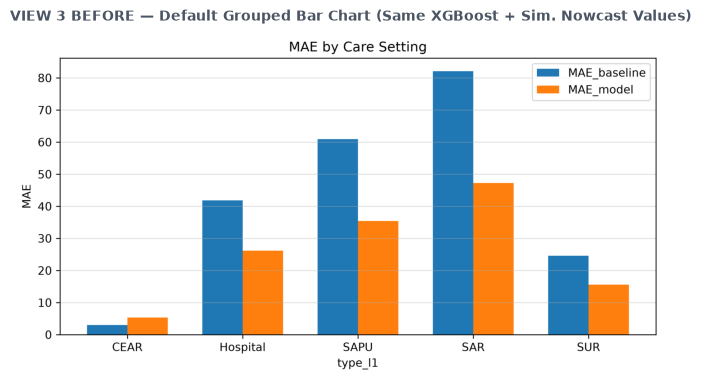

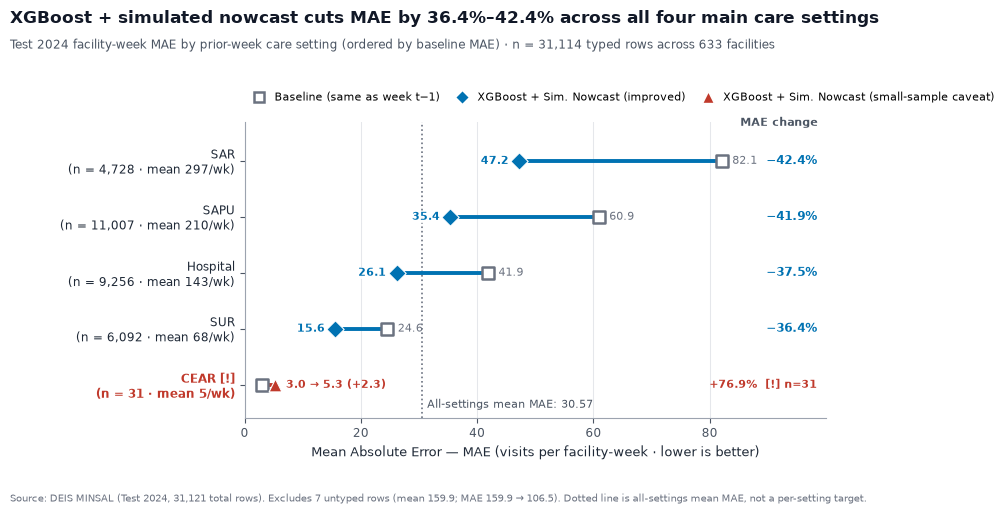

In [4]:
# Display BEFORE (unrefined default grouped bar chart with exact same values)
before3 = mpimg.imread(W3_V2_DIR / 'figures' / 'view3_before_care_setting_mae.png')
fig_b3, ax_b3 = plt.subplots(figsize=(8.6, 4.0))
ax_b3.imshow(before3); ax_b3.axis('off')
ax_b3.set_title('VIEW 3 BEFORE — Default Grouped Bar Chart (Same XGBoost + Sim. Nowcast Values)', fontsize=10, fontweight='bold', loc='left', color=PALETTE['muted'])
plt.tight_layout(); plt.show()

# Generate & display AFTER via src/visual_system.py
apply_system_rc()
df = cs_df.dropna(subset=['type_l1']).sort_values('MAE_baseline', ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10.2, 5.2))
fig.subplots_adjust(left=0.29, right=0.86, top=0.75, bottom=0.18)
style_axes(ax, grid_axis='x')
y = np.arange(len(df))

ax.axvline(30.57, color=PALETTE['baseline'], ls=':', lw=1.2, zorder=2)
ax.text(31.4, -0.46, 'All-settings mean MAE: 30.57', fontsize=7.8, color=PALETTE['muted'], ha='left', va='bottom')

for i, row in df.iterrows():
    is_caution = row['type_l1'] == 'CEAR'
    seg_color = PALETTE['alert'] if is_caution else PALETTE['model']
    ax.plot([row['MAE_baseline'], row['MAE_model']], [i, i], color=seg_color, lw=2.8, zorder=3)
    ax.scatter([row['MAE_baseline']], [i], color='white', edgecolor=PALETTE['baseline'], s=72, marker='s', lw=1.8, zorder=5)
    if is_caution:
        ax.scatter([row['MAE_model']], [i], color=PALETTE['alert'], edgecolor='white', s=85, marker='^', lw=0.8, zorder=6)
        ax.text(row['MAE_model'] + 1.8, i, f"{row['MAE_baseline']:.1f} → {row['MAE_model']:.1f} (+{row['MAE_model']-row['MAE_baseline']:.1f})",
                ha='left', va='center', fontsize=7.9, fontweight='bold', color=PALETTE['alert'])
        ax.text(98.5, i, f"+{row['MAE change (%)']:.1f}%  [!] n=31", ha='right', va='center', fontsize=8.1, fontweight='bold', color=PALETTE['alert'])
    else:
        ax.scatter([row['MAE_model']], [i], color=PALETTE['model'], edgecolor='white', s=78, marker=SERIES_STYLE['model']['marker'], lw=0.8, zorder=6)
        ax.text(row['MAE_model'] - 1.8, i, f"{row['MAE_model']:.1f}", ha='right', va='center', fontsize=8.2, fontweight='bold', color=PALETTE['model'],
                bbox=dict(boxstyle='square,pad=0.05', facecolor='white', edgecolor='none', alpha=0.85))
        ax.text(row['MAE_baseline'] + 1.8, i, f"{row['MAE_baseline']:.1f}", ha='left', va='center', fontsize=8.0, color=PALETTE['baseline'])
        ax.text(98.5, i, f"−{abs(row['MAE change (%)']):.1f}%", ha='right', va='center', fontsize=8.5, fontweight='bold', color=PALETTE['model'])

ylabels = [f"{r['type_l1']} [!]\n(n = {int(r['rows']):,} · mean {r['mean_observed']:.0f}/wk)" if r['type_l1'] == 'CEAR'
           else f"{r['type_l1']}\n(n = {int(r['rows']):,} · mean {r['mean_observed']:.0f}/wk)" for _, r in df.iterrows()]
ax.set_yticks(y); ax.set_yticklabels(ylabels, fontsize=8.3, color=PALETTE['text'])
ax.get_yticklabels()[0].set_color(PALETTE['alert']); ax.get_yticklabels()[0].set_fontweight('bold')

ax.set_xlim(0, 100); ax.set_ylim(-0.6, len(df) - 0.3); ax.set_xticks([0, 20, 40, 60, 80])
ax.set_xlabel('Mean Absolute Error — MAE (visits per facility-week · lower is better)')
ax.text(98.5, len(df) - 0.42, 'MAE change', ha='right', va='bottom', fontsize=8.1, fontweight='bold', color=PALETTE['muted'])

handles3 = [
    Line2D([0], [0], color='none', marker='s', ms=7, mfc='white', mec=PALETTE['baseline'], mew=1.8, label='Baseline (same as week t−1)'),
    Line2D([0], [0], color='none', marker=SERIES_STYLE['model']['marker'], ms=7.0, mfc=PALETTE['model'], mec='white', label='XGBoost + Sim. Nowcast (improved)'),
    Line2D([0], [0], color='none', marker='^', ms=8, mfc=PALETTE['alert'], mec='white', label='XGBoost + Sim. Nowcast (small-sample caveat)'),
]
add_top_legend(ax, handles3, ncol=3, y_offset=1.03, fontsize=7.8)
add_header_footer(
    fig,
    title='XGBoost + simulated nowcast cuts MAE by 36.4%–42.4% across all four main care settings',
    subtitle='Test 2024 facility-week MAE by prior-week care setting (ordered by baseline MAE) · n = 31,114 typed rows across 633 facilities',
    footer='Source: DEIS MINSAL (Test 2024, 31,121 total rows). Excludes 7 untyped rows (mean 159.9; MAE 159.9 → 106.5). Dotted line is all-settings mean MAE, not a per-setting target.',
)
fig.savefig(FIG_OUT / 'view3_after_care_setting_mae.png', dpi=300)
fig.savefig(FIG_OUT / 'view3_after_care_setting_mae.svg')
plt.show()

## 5. Limits, Trade-Offs & Next Improvements (4-Part Audit Across All 3 Final Views)

| Final View | Limitation | Possible Misunderstanding | Reason to Keep Design | Specific Next Improvement |
|---|---|---|---|---|
| **View 1** · Data Readiness & Sim. Nowcast | Uses a single Wednesday snapshot (`4 Nov 2026`) re-mapped to Monday and simulates `1.58%` WAPE assuming independent day-level delays. | Managers may treat `1.58%` WAPE as a measured year-round guarantee, unaware that facility-block delays during winter surges increase error. | Primary Monday task is to **locate** the 3 operational regimes (`Age 1`, `Ages 2–8`, `Ages 9–15`) in one clear view; 633 facility curves would obscure that rule. | Archive actual Monday DEIS snapshots across one winter season to measure block-correlated error and add a `10th–90th` percentile facility ribbon. |
| **View 2** · National 2024 Trajectory | Aggregates 633 facilities into one national sum without prediction intervals, and highlights a single peak-lag marker despite a flat May plateau (`182.0k` vs. `183.7k`). | Readers may assume single facilities are as smooth as the national curve, misattribute peak timing to nowcasting (lag-safe XGBoost alone hits `0-wk` lag), or assume the `6 Oct` spike has a proven cause. | Directors first need to **summarize** system-wide tracking, spot the May plateau and `6 Oct` caveat, and compare error against baseline without clutter from 3 overlapping bands. | Add a complementary `80%/95%` quantile prediction fan chart (Class 09 Slide 39) for the model alone, plus an ablation test of Fourier seasonal features. |
| **View 3** · Care-Setting MAE | Summarizes each care setting by its **mean** absolute error (MAE), hiding skewed error distributions across facilities and surge weeks. | Planners may think every `SAR` misses by `~47` visits every week, or misread `SAR`'s higher raw MAE (`47.2` vs. `SUR 15.6`) as worse relative accuracy despite `4.4x` higher volume. | Core task is rapid pairwise Baseline vs. Model comparison across all 5 settings with visible denominators (`n`); 10 paired boxplots would weaken direct delta reading. | Pair the dumbbell with a relative-error (`WAPE %`) column or a stratified raincloud/box plot (Class 09 Slide 26) splitting surge vs. off-peak weeks. |